Looking at crime data in Pittsburgh...

Let's see what we're working with - what does this data look like?

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

crime_df = pd.read_csv("data/pittsburgh_police_data.csv")
pop_df = pd.read_csv("data/pittsburgh_population_data.csv")

In [3]:
print(crime_df.shape)
print(crime_df.columns)
crime_df.head(5)

(59353, 26)
Index(['_id', 'Template', 'Report_Number', 'ArrestPerson_ID', 'Arrest_Date',
       'Arrest_Year', 'Arrest_Month', 'Arrest_Time', 'Type',
       'ArrestPerson_Age', 'ArrestPerson_Sex', 'ArrestPerson_Race',
       'NIBRS_Coded_Offense', 'NIBRS_Offense_Code', 'NIBRS_Offense_Category',
       'NIBRS_Offense_Type', 'NIBRS_Crime_Against', 'NIBRS_Offense_Grouping',
       'Violation', 'Zone', 'Tract', 'Neighborhood',
       'ArrestCharge_Felony_Misdemeanor_Description', 'XCOORD', 'YCOORD',
       'Block_Address'],
      dtype='object')


,_id,Template,Report_Number,ArrestPerson_ID,Arrest_Date,Arrest_Year,Arrest_Month,Arrest_Time,Type,ArrestPerson_Age,...,NIBRS_Crime_Against,NIBRS_Offense_Grouping,Violation,Zone,Tract,Neighborhood,ArrestCharge_Felony_Misdemeanor_Description,XCOORD,YCOORD,Block_Address
0,1,Juvenile Arrest-On View,PGHP26063901,09efaeb4-dda8-c29a-6854-08dea73d81d9,2026-04-30,2026,Apr,22:59,On-View Arrest (apprehension without a warrant...,17.0,...,Group B,B,18 3503 A1I Criminal Trespass-Enter Structure,Zone 2,511.0,Terrace Village,FELONY - F3,-79.9780,40.4423,"2000 BLOCK OF REED ST PITTSBURGH, PA"
1,2,Adult Arrest-On View,PGHP26063915,35b310bb-60f9-cf8e-45ae-08dea73f8b20,2026-05-01,2026,May,00:08,On-View Arrest (apprehension without a warrant...,62.0,...,Person,A,18 2701 A1 Simple Assault-General,Zone 2,201.0,Central Business District,MISDEMEANOR - M2,-80.0002,40.4426,"600 BLOCK OF LIBERTY AVE PITTSBURGH, PA"
2,3,Adult Arrest-Warrant (from PBP),PGHP26057645,56e0393a-37bf-c432-0a3b-08dea747fd9b,2026-05-01,2026,May,01:24,Taken Into Custody (based on a warrant and/or ...,42.0,...,Group B,B,18 3503 B1I Criminal Trespass-Defiant Trespass...,Zone 5,1702.0,Lincoln-Lemington-Belmar,MISDEMEANOR - M3,-79.8930,40.4770,NaN
3,4,Adult Arrest-Warrant (from PBP),PGHP26057645,56e0393a-37bf-c432-0a3b-08dea747fd9b,2026-05-01,2026,May,01:24,Taken Into Custody (based on a warrant and/or ...,42.0,...,Property,A,18 3929 A1 Retail Theft-Take Merchandise- Enha...,Zone 5,1702.0,Lincoln-Lemington-Belmar,MISDEMEANOR - M1,-79.8930,40.4770,NaN
4,5,Adult Arrest-On View,PGHP24000068,3b9e1fe8-c365-ce5a-3adc-08dc0aa5568f,2024-01-01,2024,Jan,01:22,On-View Arrest (apprehension without a warrant...,21.0,...,Group B,B,18 5505 Public Drunkenness,Zone 1,2205.0,North Shore,INFRACTION - S,-80.0115,40.4461,NaN


In [4]:
pop_df = pop_df[['Neighborhood', '2020_Total_Population']]
print(pop_df.shape)
print(pop_df.columns)
pop_df.head(5)

(89, 2)
Index(['Neighborhood', '2020_Total_Population'], dtype='object')


,Neighborhood,2020_Total_Population
0,Allegheny Center,1419
1,Allegheny West,540
2,Allentown,2305
3,Arlington - Arlington Heights (Combined),2040
4,Banksville,4127


59353 police data entries, not bad. I noticed there was a neighborhood attribute, let's look at that next...

In [5]:
print(crime_df["Neighborhood"].values)
print(crime_df["Neighborhood"].value_counts())

['Terrace Village' 'Central Business District' 'Lincoln-Lemington-Belmar'
 ... 'South Side Flats' 'South Side Flats' 'South Side Flats']
Neighborhood
Bluff                        8111
Central Business District    7875
South Side Flats             4171
East Allegheny               2488
Carrick                      1545
                             ... 
East Carnegie                  27
Swisshelm Park                 25
New Homestead                  24
Ridgemont                      18
St. Clair                      17
Name: count, Length: 90, dtype: int64


Some neighborhoods are already looking better than others- Bluff doesn't look great while St. Clair has only 17 incidents in the past 2.5 years. I also want to look at crime classifications - how common are felonies vs misdemeanors vs infractions?

In [6]:
print(crime_df["ArrestCharge_Felony_Misdemeanor_Description"].value_counts())

ArrestCharge_Felony_Misdemeanor_Description
MISDEMEANOR         9046
MISDEMEANOR - M2    8734
INFRACTION - S      7951
MISDEMEANOR - M1    4454
FELONY - F3         3774
MISDEMEANOR - M3    3493
FELONY - F2         2773
FELONY - F1         2405
FELONY              1632
INFRACTION - H1      498
INFRACTION            31
Name: count, dtype: int64


Mostly misdemeanors and infractions, fewer felonies. Last thing for this preliminary analysis- can we group these by neighborhood?

In [7]:
neighborhoods_grouped = crime_df.groupby("Neighborhood")["ArrestCharge_Felony_Misdemeanor_Description"]
neighborhoods_grouped.value_counts()

Neighborhood      ArrestCharge_Felony_Misdemeanor_Description
Allegheny Center  INFRACTION - S                                 97
                  MISDEMEANOR                                    96
                  MISDEMEANOR - M2                               73
                  FELONY - F1                                    64
                  MISDEMEANOR - M1                               26
                                                                 ..
Windgap           MISDEMEANOR - M3                                4
                  FELONY - F2                                     3
                  FELONY - F3                                     3
                  FELONY                                          2
                  FELONY - F1                                     1
Name: count, Length: 803, dtype: int64

In [8]:
neighborhoods_grouped.get_group("Windgap").value_counts()

,count
ArrestCharge_Felony_Misdemeanor_Description,
MISDEMEANOR - M2,14
INFRACTION - S,11
MISDEMEANOR - M1,7
MISDEMEANOR,7
MISDEMEANOR - M3,4
FELONY - F2,3
FELONY - F3,3
FELONY,2
FELONY - F1,1


In [9]:
crime_count = neighborhoods_grouped.count()

Nothing surprising about the crime type distribution: felonies are less common than misdemeanors and infractions. One flaw with this arrest data is that it isn't normalized by population. Let's try to fix that.

In [10]:
merge_df = pd.merge(crime_count, pop_df, left_on="Neighborhood", right_on="Neighborhood")
merge_df["Crime Rate"] = merge_df["ArrestCharge_Felony_Misdemeanor_Description"] / merge_df["2020_Total_Population"]
merge_df.sort_values(by="Crime Rate")

,Neighborhood,ArrestCharge_Felony_Misdemeanor_Description,2020_Total_Population,Crime Rate
76,Swisshelm Park,12,1339,0.008962
48,Morningside,36,3252,0.011070
70,Squirrel Hill North,151,11879,0.012712
30,Friendship,36,1963,0.018339
73,Stanton Heights,82,4427,0.018523
...,...,...,...,...
81,West End,221,205,1.078049
8,Bluff,6731,5882,1.144339
52,North Shore,726,301,2.411960
66,South Shore,108,29,3.724138


Four neighborhoods didn't make it into the merge - they didn't have census data. That's ok, we will drop them to keep the data clean. Another thing I'm noticing is that small neighborhoods like Chateau have huge crime rates because they have a small population. I'm going to drop neighborhoods with populations less than 100. I also want to give the neighborhoods a score from 1 to 0. I'm going to center the distribution at 0.5 and tighten the distribution, then clamp the values between 0 and 1.

In [11]:
merge_df = merge_df[merge_df["2020_Total_Population"] > 100]
merge_df.shape

(83, 4)

In [12]:
merge_df["Normalized Crime Rate"] = ((merge_df["Crime Rate"] - merge_df["Crime Rate"].mean()) / (2 * merge_df["Crime Rate"].std())) + 0.5
merge_df["Normalized Crime Rate"] = merge_df["Normalized Crime Rate"].clip(0, 1)
merge_df.sort_values(by = "Crime Rate")

,Neighborhood,ArrestCharge_Felony_Misdemeanor_Description,2020_Total_Population,Crime Rate,Normalized Crime Rate
76,Swisshelm Park,12,1339,0.008962,0.230745
48,Morningside,36,3252,0.011070,0.234003
70,Squirrel Hill North,151,11879,0.012712,0.236540
30,Friendship,36,1963,0.018339,0.245237
73,Stanton Heights,82,4427,0.018523,0.245521
...,...,...,...,...,...
38,Homewood South,1080,2260,0.477876,0.955431
22,East Allegheny,1808,1903,0.950079,1.000000
81,West End,221,205,1.078049,1.000000
8,Bluff,6731,5882,1.144339,1.000000


Nice. Now our normalized crime rate depends on how many standard deviations better or worse than average a neighborhood is. Finally, I want to remap the scores so that the very best neighborhoods have crime scores at or near one and the very worst neighborhoods have crime scores at or near zero.

In [13]:
old_min, old_max = merge_df['Normalized Crime Rate'].min(), merge_df['Normalized Crime Rate'].max()
new_min, new_max = 0, 1

merge_df["Crime Score"] = 1 - (new_min + (merge_df['Normalized Crime Rate'] - old_min) * (new_max - new_min) / (old_max - old_min))
merge_df.sort_values(by = "Crime Score")

,Neighborhood,ArrestCharge_Felony_Misdemeanor_Description,2020_Total_Population,Crime Rate,Normalized Crime Rate,Crime Score
8,Bluff,6731,5882,1.144339,1.000000,0.000000
22,East Allegheny,1808,1903,0.950079,1.000000,0.000000
52,North Shore,726,301,2.411960,1.000000,0.000000
81,West End,221,205,1.078049,1.000000,0.000000
38,Homewood South,1080,2260,0.477876,0.955431,0.057938
...,...,...,...,...,...,...
73,Stanton Heights,82,4427,0.018523,0.245521,0.980792
30,Friendship,36,1963,0.018339,0.245237,0.981161
70,Squirrel Hill North,151,11879,0.012712,0.236540,0.992467
48,Morningside,36,3252,0.011070,0.234003,0.995765


And finally we will make a graph to visualize our results...

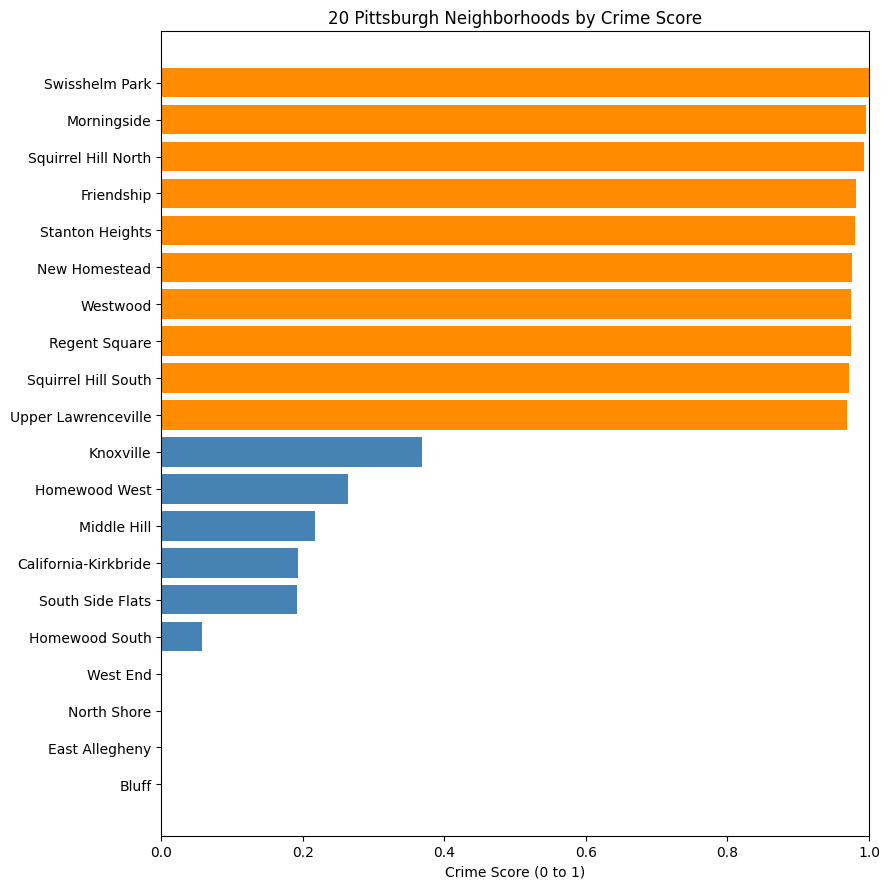

In [14]:
score_df = merge_df[["Neighborhood", "Crime Score"]]

sorted = score_df.sort_values(by = "Crime Score")
bottom10 = sorted.head(10)
top10 = sorted.tail(10)
together = pd.concat([bottom10, top10])

colors = ["darkorange" if neighborhood in top10.index else "steelblue" for neighborhood in together.index]

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(together["Neighborhood"], together["Crime Score"], color=colors)
ax.set_title("20 Pittsburgh Neighborhoods by Crime Score")
ax.set_xlabel("Crime Score (0 to 1)")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

In [15]:
score_df[score_df["Crime Score"] > 0.8].shape

(46, 2)

From this data it looks like the best neighborhoods have relatively similar crime scores. The neighborhoods our family should definitely avoid moving to are Bluff, West End, North Shore, and East Allegheny. However, with a cutoff of 0.8 there are still more than 40 neighborhoods for our family to explore!

Now let's save our results!

In [16]:
final_df = merge_df[["Neighborhood", "Crime Score"]]
print(final_df)
final_df.to_csv("data/crime_scores.csv", index=False)

           Neighborhood  Crime Score
0      Allegheny Center     0.416287
1        Allegheny West     0.612479
2             Allentown     0.644090
3            Banksville     0.941577
4     Bedford Dwellings     0.533867
..                  ...          ...
80  Upper Lawrenceville     0.969332
81             West End     0.000000
82         West Oakland     0.865782
83             Westwood     0.974592
84              Windgap     0.940274

[83 rows x 2 columns]
